# 03 · RQ2: Learn to flag large losses, then improve the warning rule
**DSC 411/511 graduate project · Venkat Repaka and Ritik Gaire**

**Question:** can we flag claims whose damage is above a "large loss" line, using only facts known about the building, policy and storm?

Notebook 02 showed that predicting exact dollars is hard. A yes/no warning is an easier question. We start with the classifiers from class, then test stronger models and different input combinations, including **claim counts per storm and place**. We also check where the warning works and where it does not.

**Course path:** lecture 05 (trees, Naive Bayes), lecture 06 (nearest neighbors, scaling), lecture 07 (logistic regression, SVM, thresholds). A large dollar loss often means a large building, not a badly damaged one. Keep this in mind.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from project_utils import *
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

task = 'classification'

df = load_joined()

## 1. Define the label without using later outcomes
We calculate the damage cutoff from the fitting period. For development that is 2020–2021; for the final refit it is 2020–2023. Missing damage is not turned into a non-severe label.

In [2]:
d = df[df.buildingDamageAmount.notna() & (df.buildingDamageAmount >= 0)].copy()

fit = d.loss_year <= 2021
valid = d.loss_year.between(2022,2023)
train = d.loss_year <= 2023
test = d.loss_year >= 2024
cut_dev = d.loc[fit,'buildingDamageAmount'].quantile(.8)
cut_final = d.loc[train,'buildingDamageAmount'].quantile(.8)
ydev = (d.buildingDamageAmount >= cut_dev).astype(int)
y = (d.buildingDamageAmount >= cut_final).astype(int)
print(f'Development cutoff: ${cut_dev:,.0f}; final cutoff: ${cut_final:,.0f}')

display(pd.Series({'fit 2020–2021':fit.sum(),'validate 2022–2023':valid.sum(),
                   'refit 2020–2023':train.sum(),'evaluate 2024–2025':test.sum()}).to_frame('claims'))

Development cutoff: $57,923; final cutoff: $83,893


,claims
fit 2020–2021,71066
validate 2022–2023,71162
refit 2020–2023,142228
evaluate 2024–2025,104233


### 1.1 Why accuracy alone is not enough
Always predicting “not large” can have high accuracy when large losses are uncommon. Flagging everything has perfect recall but many false warnings. These two baselines show why we also need precision, recall, F1 and ranking scores.

In [3]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,average_precision_score
base_rows=[]
for name,pred in [('flag none',np.zeros(valid.sum())),('flag every claim',np.ones(valid.sum()))]:
    base_rows.append({'rule':name,'accuracy':accuracy_score(ydev[valid],pred),
                     **classification_scores(ydev[valid],pred,.5)})
display(pd.DataFrame(base_rows).set_index('rule').round(3))
print(f'Development large-loss share: fit {ydev[fit].mean():.1%}; validation {ydev[valid].mean():.1%}')

,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
rule,,,,,,
flag none,0.621,0.000,0.000,0.000,0.500,0.379
flag every claim,0.379,0.379,1.000,0.550,0.500,0.379


Development large-loss share: fit 20.0%; validation 37.9%


### Scores we will use throughout the sequence

| Score | Simple meaning | Main caution |
|---|---|---|
| Accuracy | Share of all labels predicted correctly | Can hide failure on a small important class |
| Precision | Share of flagged claims that really are large losses | More false warnings reduce it |
| Recall | Share of large losses found | Flagging everyone gives 100% recall |
| F1 | A combined precision and recall score | Depends on the warning cutoff and class mix |
| ROC-AUC | How well the score ranks the two classes | 0.5 is random ranking; it is not a warning policy |
| PR-AUC | Average precision across the recall range | Compare it with the large-loss share in that period |

We use **average precision** for the PR-AUC column. Class-balanced fitting and moving the cutoff are different ways to change warning behavior. Neither proves that the score is a reliable probability.

## 2. Learn the course methods on the same manageable sample
We use 8,000 fitting claims and up to 6,000 validation claims for the teaching comparisons. This keeps expensive distance and kernel methods practical. These sample results are not our final national evaluation.

All five course classifiers will use the same sample and features. For the scaling lesson, raw coverage dollars are included so that their large scale is visible.

In [4]:
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.model_selection import GroupKFold,cross_val_score
from sklearn.base import clone
bridge_cols=['totalBuildingInsuranceCoverage','totalContentsInsuranceCoverage','building_age','policyCount',
             'deductible_usd','crsClassCode','zone','foundation','occupancy','state']
learn=d.loc[fit].sample(min(8000,fit.sum()),random_state=SEED)
check=d.loc[valid].sample(min(6000,valid.sum()),random_state=SEED)
Xlearn=learn[bridge_cols];Xcheck=check[bridge_cols]
ylearn=ydev.loc[learn.index];ycheck=ydev.loc[check.index]
groups=learn.floodEvent.fillna('unnamed-'+learn.loss_year.astype(str))
course_results=[]
def record_course(name,model):
    model.fit(Xlearn,ylearn)
    score=model.predict_proba(Xcheck)[:,1] if hasattr(model,'predict_proba') else model.decision_function(Xcheck)
    threshold=.5 if hasattr(model,'predict_proba') else 0
    course_results.append({'model':name,**classification_scores(ycheck,score,threshold)})
    display(pd.DataFrame(course_results).set_index('model').round(3))
    return model

### 2.1 Start with a readable decision tree
A depth-two tree makes a small number of decisions. Balanced class weights give more fitting weight to the less common class. The displayed node fractions are weighted fitting values, not unweighted population probabilities.

,precision,recall,F1,ROC-AUC,PR-AUC
model,,,,,
tree depth 2,0.487,0.856,0.621,0.646,0.469


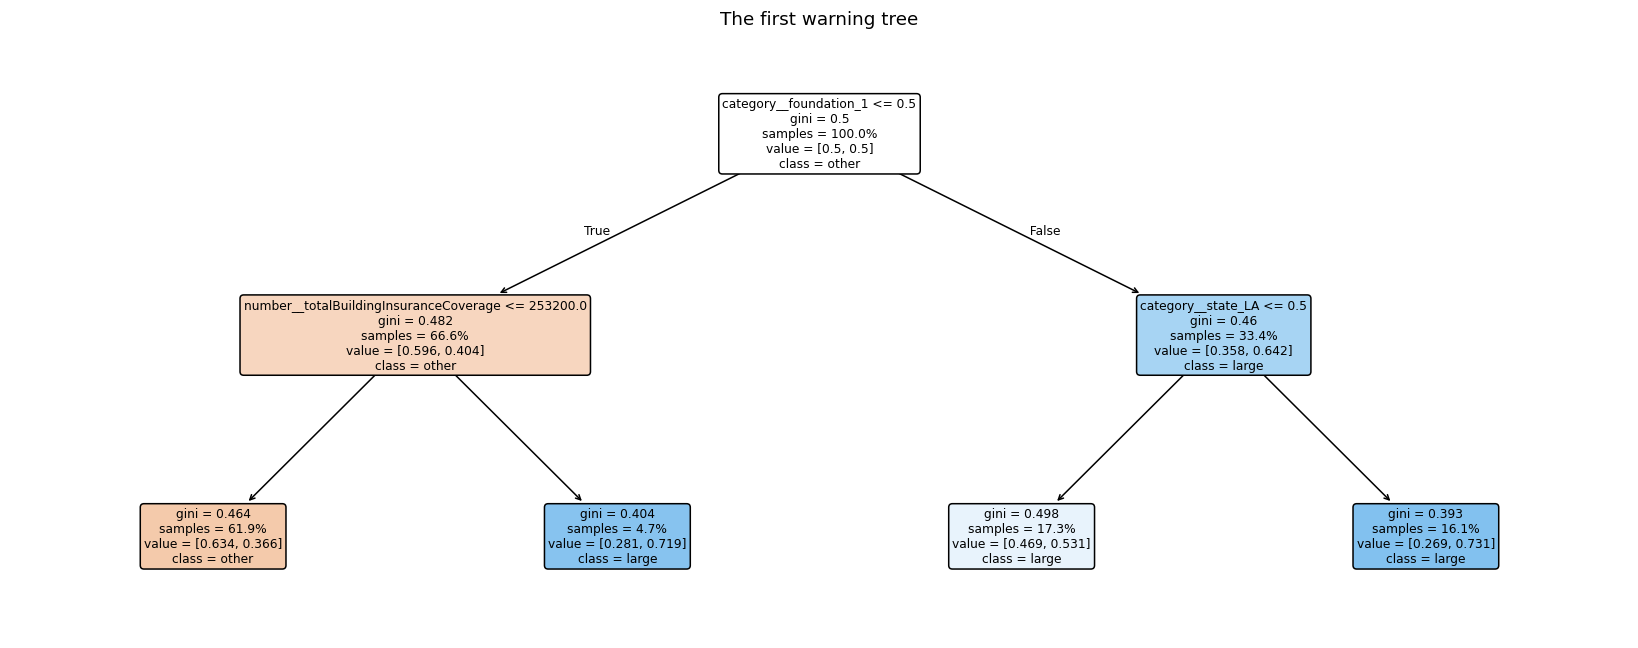

In [5]:
small_tree=record_course('tree depth 2',make_pipeline(prepare(Xlearn),
    DecisionTreeClassifier(max_depth=2,class_weight='balanced',min_samples_leaf=20,random_state=SEED)))
plt.figure(figsize=(15,6))
plot_tree(small_tree.steps[-1][1],feature_names=small_tree.steps[0][1].get_feature_names_out(),
          class_names=['other','large'],filled=True,rounded=True,fontsize=8,proportion=True)
plt.title('The first warning tree');plt.tight_layout();plt.show()

### 2.2 Choose depth using fitting data, not the later years
We try several depths with three folds that keep each storm together, inside the fitting sample. The validation years stay outside this step. We score each depth with PR-AUC, which judges the *ranking* of claims. We do not use F1 here, because F1 depends on a cutoff that we choose later in section 8.

,event-CV PR-AUC
2,0.245
4,0.293
6,0.317
8,0.318
10,0.312


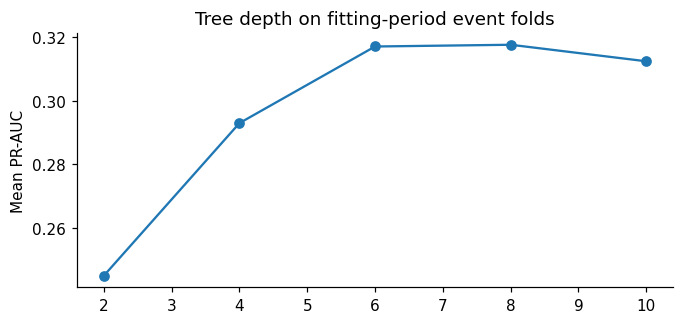

,precision,recall,F1,ROC-AUC,PR-AUC
model,,,,,
tree depth 2,0.487,0.856,0.621,0.646,0.469
tuned tree,0.497,0.566,0.529,0.647,0.503


Depth frozen for the main course-tree candidate: 8


In [6]:
depth_scores={}
for depth in [2,4,6,8,10]:
    model=make_pipeline(prepare(Xlearn),DecisionTreeClassifier(max_depth=depth,min_samples_leaf=20,class_weight='balanced',random_state=SEED))
    depth_scores[depth]=cross_val_score(model,Xlearn,ylearn,cv=GroupKFold(3),groups=groups,scoring='average_precision').mean()
best_depth=int(pd.Series(depth_scores).idxmax())
display(pd.Series(depth_scores,name='event-CV PR-AUC').to_frame().round(3))
pd.Series(depth_scores).plot(marker='o',figsize=(7,3),title='Tree depth on fitting-period event folds');plt.ylabel('Mean PR-AUC');plt.show()
course_tree=record_course('tuned tree',make_pipeline(prepare(Xlearn),
    DecisionTreeClassifier(max_depth=best_depth,min_samples_leaf=20,class_weight='balanced',random_state=SEED)))
print('Depth frozen for the main course-tree candidate:',best_depth)

### 2.3 Try Naive Bayes before adding more complexity
Gaussian Naive Bayes combines simple feature distributions and assumes that inputs are independent within a class. Our EDA showed related policy and building features, so the assumption is imperfect. A weak result is useful evidence about this simple model; it is not a reason to hide it.

In [7]:
bayes=record_course('Gaussian Naive Bayes',make_pipeline(prepare(Xlearn,scale=True),GaussianNB(var_smoothing=1e-7)))

,precision,recall,F1,ROC-AUC,PR-AUC
model,,,,,
tree depth 2,0.487,0.856,0.621,0.646,0.469
tuned tree,0.497,0.566,0.529,0.647,0.503
Gaussian Naive Bayes,0.418,0.931,0.577,0.567,0.419


## 3. Nearest neighbors: make the meaning of distance visible
First use the raw units, then scale the numeric fields. We change only scaling. A different result shows why distance needs a deliberate definition.

In [8]:
knn_raw=record_course('KNN raw units',make_pipeline(prepare(Xlearn),KNeighborsClassifier(n_neighbors=15,n_jobs=2)))
knn_scaled=record_course('KNN scaled',make_pipeline(prepare(Xlearn,scale=True),KNeighborsClassifier(n_neighbors=15,n_jobs=2)))

,precision,recall,F1,ROC-AUC,PR-AUC
model,,,,,
tree depth 2,0.487,0.856,0.621,0.646,0.469
tuned tree,0.497,0.566,0.529,0.647,0.503
Gaussian Naive Bayes,0.418,0.931,0.577,0.567,0.419
KNN raw units,0.574,0.064,0.116,0.606,0.466


,precision,recall,F1,ROC-AUC,PR-AUC
model,,,,,
tree depth 2,0.487,0.856,0.621,0.646,0.469
tuned tree,0.497,0.566,0.529,0.647,0.503
Gaussian Naive Bayes,0.418,0.931,0.577,0.567,0.419
KNN raw units,0.574,0.064,0.116,0.606,0.466
KNN scaled,0.513,0.043,0.079,0.649,0.482


### 3.1 Choose k and compare Euclidean with Manhattan distance
A small k follows local detail; a large k is smoother. We compare the settings on fitting-period folds that keep each storm together, using PR-AUC, the same ranking score as above.

In [9]:
knn_rows=[]
for k in [5,15,51]:
    for distance in [1,2]:
        model=make_pipeline(prepare(Xlearn,scale=True),KNeighborsClassifier(n_neighbors=k,p=distance,n_jobs=2))
        score=cross_val_score(model,Xlearn,ylearn,cv=GroupKFold(3),groups=groups,scoring='average_precision').mean()
        knn_rows.append({'k':k,'p':distance,'event-CV PR-AUC':score})
knn_settings=pd.DataFrame(knn_rows).sort_values('event-CV PR-AUC',ascending=False)
best_k=int(knn_settings.iloc[0]['k']);best_p=int(knn_settings.iloc[0]['p'])
display(knn_settings.round(3))
course_knn=record_course('KNN tuned',make_pipeline(prepare(Xlearn,scale=True),KNeighborsClassifier(n_neighbors=best_k,p=best_p,n_jobs=2)))

,k,p,event-CV PR-AUC
5,51,2,0.300
4,51,1,0.293
3,15,2,0.285
2,15,1,0.279
0,5,1,0.258
1,5,2,0.256


,precision,recall,F1,ROC-AUC,PR-AUC
model,,,,,
tree depth 2,0.487,0.856,0.621,0.646,0.469
tuned tree,0.497,0.566,0.529,0.647,0.503
Gaussian Naive Bayes,0.418,0.931,0.577,0.567,0.419
KNN raw units,0.574,0.064,0.116,0.606,0.466
KNN scaled,0.513,0.043,0.079,0.649,0.482
KNN tuned,0.520,0.017,0.033,0.669,0.506


### 3.2 Does PCA help the distance method?
Lecture 06 tested PCA before neighbors. We keep 80% of input variation inside the fitting pipeline and compare with tuned KNN. PCA can remove noise, but it can also remove a small-variance signal that matters for the label.

In [10]:
from sklearn.decomposition import PCA
knn_pca=record_course('KNN with PCA',make_pipeline(prepare(Xlearn,scale=True),PCA(n_components=.8,svd_solver='full'),
    KNeighborsClassifier(n_neighbors=best_k,p=best_p,n_jobs=2)))

,precision,recall,F1,ROC-AUC,PR-AUC
model,,,,,
tree depth 2,0.487,0.856,0.621,0.646,0.469
tuned tree,0.497,0.566,0.529,0.647,0.503
Gaussian Naive Bayes,0.418,0.931,0.577,0.567,0.419
KNN raw units,0.574,0.064,0.116,0.606,0.466
KNN scaled,0.513,0.043,0.079,0.649,0.482
KNN tuned,0.520,0.017,0.033,0.669,0.506
KNN with PCA,0.421,0.043,0.078,0.630,0.463


**Checkpoint · What the result changes**

On the common teaching sample, scaling KNN changes ROC-AUC from **0.606** to **0.649**, while F1 changes from **0.116** to **0.079**. Ranking and a fixed-cutoff warning score can move differently. At the tuned settings, PCA changes F1 from **0.033** to **0.078**. Even then, the warning performance can remain weak.

## 4. Logistic regression: a score with readable directions
Logistic regression turns a weighted sum into a score between 0 and 1. Balanced weights change the fitting objective, so the result is not automatically a well-calibrated population probability.

A positive coefficient points toward the large-loss class in this fitted comparison. It does not show that the feature causes a large loss.

In [11]:
logistic=record_course('logistic regression',make_pipeline(prepare(Xlearn,scale=True),
    LogisticRegression(C=.1,class_weight='balanced',max_iter=1500)))
names=logistic.steps[0][1].get_feature_names_out()
weights=pd.Series(logistic.steps[-1][1].coef_[0],index=names)
display(weights.reindex(weights.abs().nlargest(10).index).to_frame('fitted coefficient').round(3))

,precision,recall,F1,ROC-AUC,PR-AUC
model,,,,,
tree depth 2,0.487,0.856,0.621,0.646,0.469
tuned tree,0.497,0.566,0.529,0.647,0.503
Gaussian Naive Bayes,0.418,0.931,0.577,0.567,0.419
KNN raw units,0.574,0.064,0.116,0.606,0.466
KNN scaled,0.513,0.043,0.079,0.649,0.482
KNN tuned,0.520,0.017,0.033,0.669,0.506
KNN with PCA,0.421,0.043,0.078,0.630,0.463
logistic regression,0.524,0.759,0.620,0.705,0.541


,fitted coefficient
category__state_LA,1.081
category__foundation_1,0.931
category__occupancy_13,0.868
category__foundation_5,-0.779
category__state_MI,0.653
category__foundation_6,-0.633
category__state_TN,0.605
category__occupancy_15,0.592
category__state_SC,-0.591
category__occupancy_14,-0.589


### 4.1 Trace one prediction
This shows the weighted sum and sigmoid for one record. It explains the calculation, not the truth of the prediction.

In [12]:
encoded=logistic.steps[0][1].transform(Xcheck.iloc[[0]])
linear_score=float((encoded @ logistic.steps[-1][1].coef_[0] + logistic.steps[-1][1].intercept_[0])[0])
probability=1/(1+np.exp(-linear_score))
display(Xcheck.iloc[[0]])
print(f'Weighted sum: {linear_score:.3f}; sigmoid score: {probability:.3f}; recorded label: {int(ycheck.iloc[0])}')

,totalBuildingInsuranceCoverage,totalContentsInsuranceCoverage,building_age,policyCount,deductible_usd,crsClassCode,zone,foundation,occupancy,state
24930,"2,500,000.000",0.000,33.739,10.000,"5,000.000",5.000,AE,5,15,FL


Weighted sum: -0.316; sigmoid score: 0.422; recorded label: 1


## 5. SVM: compare a boundary defined by difficult cases
An RBF SVM can learn a curved boundary. It uses scaled inputs and is more expensive on large samples. Its decision score is not a probability, so we evaluate ranking and classify at score zero for this course comparison.

In [13]:
svm=record_course('RBF SVM',make_pipeline(prepare(Xlearn,scale=True),SVC(C=1,kernel='rbf',class_weight='balanced')))
print('Support vectors:',svm.steps[-1][1].n_support_.sum(),'of',len(learn),'fitting cases')
course_table=pd.DataFrame(course_results).set_index('model')
display(course_table.round(3));save_table(course_table,'03_course_classifiers')

,precision,recall,F1,ROC-AUC,PR-AUC
model,,,,,
tree depth 2,0.487,0.856,0.621,0.646,0.469
tuned tree,0.497,0.566,0.529,0.647,0.503
Gaussian Naive Bayes,0.418,0.931,0.577,0.567,0.419
KNN raw units,0.574,0.064,0.116,0.606,0.466
KNN scaled,0.513,0.043,0.079,0.649,0.482
KNN tuned,0.520,0.017,0.033,0.669,0.506
KNN with PCA,0.421,0.043,0.078,0.630,0.463
logistic regression,0.524,0.759,0.620,0.705,0.541
RBF SVM,0.534,0.649,0.586,0.700,0.536


Support vectors: 5437 of 8000 fitting cases


,precision,recall,F1,ROC-AUC,PR-AUC
model,,,,,
tree depth 2,0.487,0.856,0.621,0.646,0.469
tuned tree,0.497,0.566,0.529,0.647,0.503
Gaussian Naive Bayes,0.418,0.931,0.577,0.567,0.419
KNN raw units,0.574,0.064,0.116,0.606,0.466
KNN scaled,0.513,0.043,0.079,0.649,0.482
KNN tuned,0.520,0.017,0.033,0.669,0.506
KNN with PCA,0.421,0.043,0.078,0.630,0.463
logistic regression,0.524,0.759,0.620,0.705,0.541
RBF SVM,0.534,0.649,0.586,0.700,0.536


### 5.1 Keep the lesson from every model
Tree depth controls detail. Naive Bayes is fast but assumes simple feature distributions. KNN depends on scaling, k and distance. Logistic regression is a useful simple score. SVM can fit a more complex boundary but costs more.

These sample comparisons teach method behavior. Next we use the full development validation population, the core engineered features from EDA, and a declared fitting budget for costly methods. We do not call the best sample row the final national model.

**Checkpoint · What the result changes**

The strongest teaching-sample model by PR-AUC is **logistic regression**, with **0.541**. This is not yet a national comparison. Next we change to the engineered core inputs and full validation population. Settings carried from the teaching experiment are reasonable candidates, not proven optimal settings for that new representation.

## 6. Define the main candidates visibly
The course candidates keep the tuning choices made inside fitting data. Forests and boosting extend the single tree. All missing-value replacement and category encoding stay inside their fitting pipelines.

KNN and SVM use at most 12,000 fitting claims, forests at most 80,000, and the other models use all fitting claims. This is a practical resource comparison, not proof that each method reached its best possible score.

In [14]:
import time

def make_model(X,task,family):
    if family=='course tree':
        return make_pipeline(prepare(X),DecisionTreeClassifier(max_depth=best_depth,min_samples_leaf=20,class_weight='balanced',random_state=SEED))
    if family=='Naive Bayes':
        return make_pipeline(prepare(X,scale=True),GaussianNB(var_smoothing=1e-7))
    if family=='KNN':
        return make_pipeline(prepare(X,scale=True),KNeighborsClassifier(n_neighbors=best_k,p=best_p,n_jobs=2))
    if family=='SVM':
        # Enable probability estimation from fitting data only for later threshold comparisons.
        return make_pipeline(prepare(X,scale=True),SVC(C=1,kernel='rbf',class_weight='balanced',probability=True,random_state=SEED))
    return candidate_model(X,task,family)

def fitting_ids(mask,family):
    ids=d.index[mask]
    limit=12000 if family in ['KNN','SVM'] else 80000 if family=='forest' else len(ids)
    return d.loc[ids].sample(min(limit,len(ids)),random_state=SEED).index if len(ids)>limit else ids

rows=[];validation_predictions={}
def try_classifiers(candidates):
    for features,family in candidates:
        started=time.monotonic();cols=FEATURE_SETS[features]
        model=make_model(d[cols],task,family)
        ids=fitting_ids(fit,family)
        model.fit(d.loc[ids,cols],ydev.loc[ids]);p=model.predict_proba(d.loc[valid,cols])[:,1]
        key=features+' | '+family;validation_predictions[key]=p
        rows.append({'candidate':key,'features':features,'family':family,**classification_scores(ydev[valid],p)})
        print(f'Finished {key} in {time.monotonic()-started:.1f} seconds',flush=True)
    table=pd.DataFrame(rows).set_index('candidate').sort_values('PR-AUC',ascending=False)
    display(table.round(3));return table

### 6.1 Course methods first, using the main core inputs
We select the final candidate by validation PR-AUC, which judges ranking of the large-loss class. Precision, recall and F1 in this comparison use a 0.50 cutoff; the final warning cutoff is chosen later.

In [15]:
course_main=try_classifiers([('core',f) for f in ['course tree','Naive Bayes','KNN','linear','SVM']])

Finished core | course tree in 0.7 seconds


Finished core | Naive Bayes in 0.4 seconds


Finished core | KNN in 4.0 seconds


Finished core | linear in 1.3 seconds


Finished core | SVM in 128.8 seconds


,features,family,precision,recall,F1,ROC-AUC,PR-AUC
candidate,,,,,,,
core | SVM,core,SVM,0.700,0.220,0.335,0.772,0.625
core | linear,core,linear,0.566,0.784,0.658,0.767,0.624
core | course tree,core,course tree,0.606,0.583,0.594,0.730,0.578
core | KNN,core,KNN,0.543,0.074,0.130,0.708,0.533
core | Naive Bayes,core,Naive Bayes,0.425,0.926,0.583,0.641,0.467


### 6.2 Add ensembles and regularization
We ask whether combining trees adds useful ranking beyond the course models. A smaller boosting model checks whether extra detail was hurting transfer.

In [16]:
ensemble_main=try_classifiers([('core','forest'),('core','boosting'),('core','small boosting')])

Finished core | forest in 1.6 seconds


Finished core | boosting in 9.3 seconds


Finished core | small boosting in 9.4 seconds


,features,family,precision,recall,F1,ROC-AUC,PR-AUC
candidate,,,,,,,
core | boosting,core,boosting,0.742,0.112,0.195,0.791,0.659
core | small boosting,core,small boosting,0.725,0.072,0.130,0.778,0.641
core | forest,core,forest,0.626,0.667,0.646,0.780,0.639
core | SVM,core,SVM,0.700,0.220,0.335,0.772,0.625
core | linear,core,linear,0.566,0.784,0.658,0.767,0.624
core | course tree,core,course tree,0.606,0.583,0.594,0.730,0.578
core | KNN,core,KNN,0.543,0.074,0.130,0.708,0.533
core | Naive Bayes,core,Naive Bayes,0.425,0.926,0.583,0.641,0.467


**Checkpoint · What the result changes**

The best main course candidate is **core | SVM** (PR-AUC **0.625**). Core boosting gives **0.659**. Read the fitting budgets and printed runtimes too. The next step keeps the boosting learner fixed and changes the information supplied to it.

## 7. Add sources in the same order as EDA
First compare policy with building/place information, then rain, tracks and their combination. These measures are retrospective: their historical first-day availability has not been verified.

In [17]:
hazard_main=try_classifiers([('policy only','boosting'),('building + place','boosting'),
    ('core + rain','boosting'),('core + track','boosting'),('core + rain + track','boosting'),('compact hazards','boosting')])

Finished policy only | boosting in 1.4 seconds


Finished building + place | boosting in 6.6 seconds


Finished core + rain | boosting in 9.2 seconds


Finished core + track | boosting in 9.6 seconds


Finished core + rain + track | boosting in 10.4 seconds


Finished compact hazards | boosting in 8.2 seconds


,features,family,precision,recall,F1,ROC-AUC,PR-AUC
candidate,,,,,,,
core | boosting,core,boosting,0.742,0.112,0.195,0.791,0.659
core | small boosting,core,small boosting,0.725,0.072,0.130,0.778,0.641
core | forest,core,forest,0.626,0.667,0.646,0.780,0.639
core + track | boosting,core + track,boosting,0.733,0.089,0.159,0.773,0.633
core | SVM,core,SVM,0.700,0.220,0.335,0.772,0.625
core | linear,core,linear,0.566,0.784,0.658,0.767,0.624
compact hazards | boosting,compact hazards,boosting,0.747,0.067,0.124,0.767,0.620
building + place | boosting,building + place,boosting,0.689,0.028,0.053,0.763,0.606
core + rain + track | boosting,core + rain + track,boosting,0.703,0.082,0.146,0.757,0.604


### 7.1 Add Census context last
Neighborhood context may repeat building and policy information. We keep the all-source result even if it is weak. A feature can be related to damage and still fail to improve a model on new events.

In [18]:
all_main=try_classifiers([('core + census','boosting'),('all sources','boosting')])

Finished core + census | boosting in 8.8 seconds


Finished all sources | boosting in 10.8 seconds


,features,family,precision,recall,F1,ROC-AUC,PR-AUC
candidate,,,,,,,
core | boosting,core,boosting,0.742,0.112,0.195,0.791,0.659
core + census | boosting,core + census,boosting,0.741,0.084,0.150,0.785,0.651
core | small boosting,core,small boosting,0.725,0.072,0.130,0.778,0.641
core | forest,core,forest,0.626,0.667,0.646,0.780,0.639
core + track | boosting,core + track,boosting,0.733,0.089,0.159,0.773,0.633
core | SVM,core,SVM,0.700,0.220,0.335,0.772,0.625
core | linear,core,linear,0.566,0.784,0.658,0.767,0.624
compact hazards | boosting,compact hazards,boosting,0.747,0.067,0.124,0.767,0.620
building + place | boosting,building + place,boosting,0.689,0.028,0.053,0.763,0.606


### 7.2 Combine the sources: how many claims came from the same storm and place?
As in notebook 02, the extra sources describe weather and neighborhoods but not how widely a storm flooded one area. We add counts of claims from the same block group, county and state in the same storm, and four simple ratios (condo or not, coverage per unit, storm strength, wind on the right side). We use claim counts only, never payments or damage. These counts are known only after claims arrive, so this is a retrospective comparison.

We test the new inputs alone and with older sources, using boosting, a straight-line model and a forest.

In [19]:
mix_main=try_classifiers([('core + local counts','boosting'),('core + claim counts','boosting'),('core + claim counts','linear'),
    ('core + claim counts','forest'),('core + ratios','boosting'),('core + track + claim counts','boosting'),
    ('best mix','boosting'),('every source + mix','boosting')])

Finished core + local counts | boosting in 8.8 seconds


Finished core + claim counts | boosting in 7.7 seconds


Finished core + claim counts | linear in 1.1 seconds


Finished core + claim counts | forest in 1.6 seconds


Finished core + ratios | boosting in 8.9 seconds


Finished core + track + claim counts | boosting in 12.1 seconds


Finished best mix | boosting in 11.1 seconds


Finished every source + mix | boosting in 12.8 seconds


,features,family,precision,recall,F1,ROC-AUC,PR-AUC
candidate,,,,,,,
core + claim counts | boosting,core + claim counts,boosting,0.685,0.532,0.599,0.802,0.684
core + claim counts | linear,core + claim counts,linear,0.564,0.841,0.675,0.798,0.680
core + claim counts | forest,core + claim counts,forest,0.565,0.845,0.677,0.798,0.677
core + local counts | boosting,core + local counts,boosting,0.691,0.480,0.567,0.797,0.676
core + ratios | boosting,core + ratios,boosting,0.712,0.406,0.517,0.793,0.674
core + track + claim counts | boosting,core + track + claim counts,boosting,0.671,0.508,0.578,0.786,0.670
best mix | boosting,best mix,boosting,0.632,0.591,0.611,0.780,0.664
every source + mix | boosting,every source + mix,boosting,0.646,0.513,0.572,0.777,0.659
core | boosting,core,boosting,0.742,0.112,0.195,0.791,0.659


**Checkpoint · What the result changes**

Core boosting has PR-AUC **0.659**. Adding claim counts gives **0.684** with boosting and **0.680** with a straight-line model. Mixing in every source does not do better than the claim counts alone. More columns are not always better.

### Before choosing a winner: are the score gaps convincing?

We keep claims from the same named event together. Unnamed claims form one block per year. The block table shows how few independent event groups are available. In 1,000 bootstrap draws, we sample whole blocks with replacement and give every candidate the same draw. The 2.5% and 97.5% limits describe the middle 95% of these resampled scores. For a paired difference, a band crossing zero means the apparent gain is not clear under this check.

We also remove each evaluation block once, keeping the fitted predictions fixed. This tests whether one event changes the conclusion; it is different from the later section that refits after excluding a storm.

**Limits:** these are descriptive event-bootstrap bands, not proof of significance or a reliable interval for every future storm. There are few events, and claims can also be related across events. The models are not refitted in the bootstrap, so fitting uncertainty is excluded. The bands are not adjusted for the many candidates or cutoff choices. The highest validation score can be partly luck. We keep the original winner as a working choice, without claiming it is clearly better. A new, untouched storm period or nested event-level model selection would be needed for stronger evidence.

In [20]:
from model_audit import event_labels, event_score_audit
uncertainty, paired_gaps, omitted_gaps, event_blocks = event_score_audit(
    ydev[valid], validation_predictions, event_labels(d.loc[valid]),
    metric='PR-AUC', pairs=[('core | boosting', 'core | forest'), ('core | boosting', 'core | SVM'), ('core + track | boosting', 'core | boosting'), ('core + rain | boosting', 'core | boosting'), ('core + claim counts | boosting', 'core | boosting'), ('core + claim counts | linear', 'core + claim counts | boosting')], repeats=1000, seed=SEED)
display(event_blocks)
print('Validation event blocks:', len(event_blocks), '; candidates:', len(validation_predictions))
display(uncertainty.sort_values('PR-AUC',ascending=False).round(3))
display(paired_gaps.round(3))
save_table(event_blocks,'03_validation_event_blocks')
save_table(uncertainty,'03_validation_uncertainty')
save_table(paired_gaps,'03_validation_paired_gaps')
save_table(omitted_gaps,'03_validation_omit_event_gaps')
for label,row in paired_gaps.iterrows():
    reading='crosses zero; no clear gain under this check' if row['paired 2.5%']<=0<=row['paired 97.5%'] else 'does not cross zero, but selection and few-event limits remain'
    display(Markdown(f"**{label}:** difference {row['difference']:+.3f}, paired band [{row['paired 2.5%']:+.3f}, {row['paired 97.5%']:+.3f}]; {reading}."))

,claims
event,
Hurricane Ian,42631
unnamed-2022,6055
Hurricane Idalia,5142
unnamed-2023,4979
April Florida Flooding,3233
December Nor'easter,1810
California Atmospheric River,1640
Late-September New York Flooding,1468
Hurricane Nicole,1353


Validation event blocks: 27 ; candidates: 24


,PR-AUC,event bootstrap 2.5%,event bootstrap 97.5%,omit-event minimum,omit-event maximum,valid bootstrap draws
candidate,,,,,,
core + claim counts | boosting,0.684,0.401,0.703,0.603,0.690,1000
core + claim counts | linear,0.680,0.407,0.700,0.608,0.688,1000
core + claim counts | forest,0.677,0.423,0.696,0.614,0.683,1000
core + local counts | boosting,0.676,0.423,0.695,0.621,0.682,1000
core + ratios | boosting,0.674,0.419,0.695,0.586,0.680,1000
core + track + claim counts | boosting,0.670,0.416,0.691,0.582,0.676,1000
best mix | boosting,0.664,0.408,0.686,0.594,0.670,1000
every source + mix | boosting,0.659,0.431,0.682,0.580,0.666,1000
core | boosting,0.659,0.404,0.690,0.577,0.669,1000


,difference,paired 2.5%,paired 97.5%,omit-event minimum,omit-event maximum
comparison,,,,,
core | boosting minus core | forest,0.020,0.002,0.041,0.017,0.034
core | boosting minus core | SVM,0.034,0.022,0.054,0.031,0.038
core + track | boosting minus core | boosting,-0.025,-0.102,0.023,-0.064,-0.014
core + rain | boosting minus core | boosting,-0.058,-0.094,0.054,-0.060,-0.050
core + claim counts | boosting minus core | boosting,0.026,-0.007,0.056,0.021,0.035
core + claim counts | linear minus core + claim counts | boosting,-0.004,-0.017,0.031,-0.007,0.006


**core | boosting minus core | forest:** difference +0.020, paired band [+0.002, +0.041]; does not cross zero, but selection and few-event limits remain.

**core | boosting minus core | SVM:** difference +0.034, paired band [+0.022, +0.054]; does not cross zero, but selection and few-event limits remain.

**core + track | boosting minus core | boosting:** difference -0.025, paired band [-0.102, +0.023]; crosses zero; no clear gain under this check.

**core + rain | boosting minus core | boosting:** difference -0.058, paired band [-0.094, +0.054]; crosses zero; no clear gain under this check.

**core + claim counts | boosting minus core | boosting:** difference +0.026, paired band [-0.007, +0.056]; crosses zero; no clear gain under this check.

**core + claim counts | linear minus core + claim counts | boosting:** difference -0.004, paired band [-0.017, +0.031]; crosses zero; no clear gain under this check.

**Checkpoint · What the result changes**

Boosting PR-AUC is **0.659** with core features, **0.600** with rain, **0.633** with tracks, and **0.588** with all sources. A successful join is not automatically a useful predictive feature. We keep the weaker combinations visible.

**Checkpoint · What the result changes**

Boosting versus the forest has a point difference of **+0.020**, with a paired event-bootstrap band **[+0.002, +0.041]**. There are **27 evaluation blocks**, many small, and the largest contains **59.9%** of validation claims. The band does not cross zero, but this does not remove the selection problem. Removing **December Nor'easter** changes the gap to **+0.017**. We keep the original highest-scoring model as a working choice. These fixed-model bands do not correct for searching many candidates or prove performance on a new storm.

## 8. Freeze the model before moving the warning threshold
This table contains the declared main candidates. It is different from the smaller teaching table. We select by ranking first, then choose the warning cutoff using validation F1.

The ranking selects a working model, not a statistically established winner. Read the paired bands and event-deletion results before describing any small gap as an improvement.

,features,family,precision,recall,F1,ROC-AUC,PR-AUC
candidate,,,,,,,
core + claim counts | boosting,core + claim counts,boosting,0.685,0.532,0.599,0.802,0.684
core + claim counts | linear,core + claim counts,linear,0.564,0.841,0.675,0.798,0.680
core + claim counts | forest,core + claim counts,forest,0.565,0.845,0.677,0.798,0.677
core + local counts | boosting,core + local counts,boosting,0.691,0.480,0.567,0.797,0.676
core + ratios | boosting,core + ratios,boosting,0.712,0.406,0.517,0.793,0.674
core + track + claim counts | boosting,core + track + claim counts,boosting,0.671,0.508,0.578,0.786,0.670
best mix | boosting,best mix,boosting,0.632,0.591,0.611,0.780,0.664
every source + mix | boosting,every source + mix,boosting,0.646,0.513,0.572,0.777,0.659
core | boosting,core,boosting,0.742,0.112,0.195,0.791,0.659


Choice frozen from validation: core + claim counts | boosting


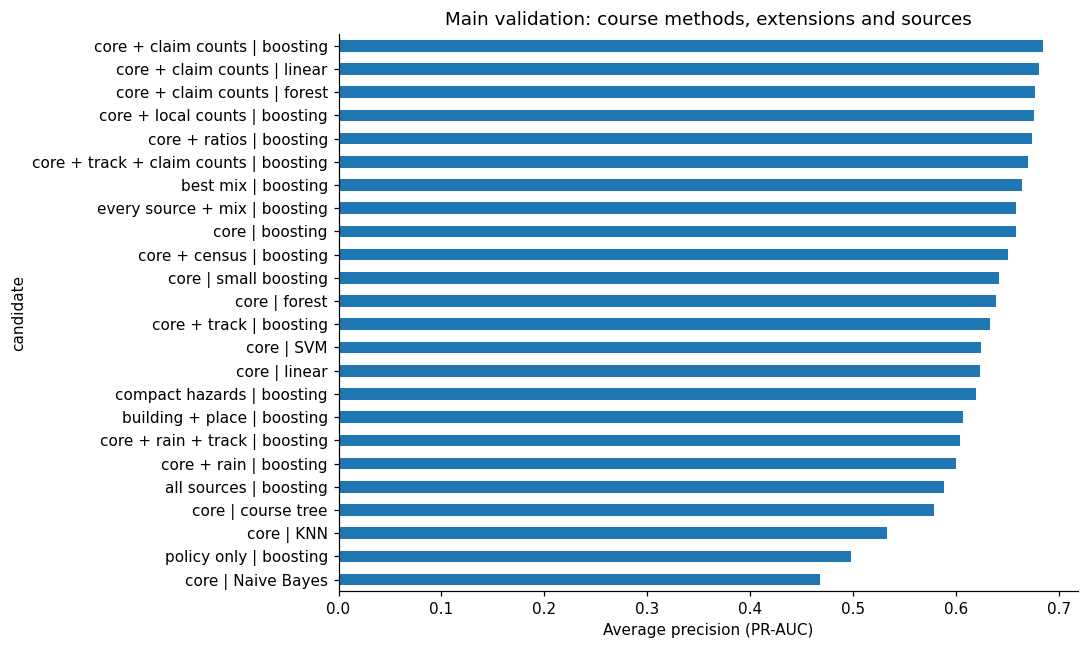

In [21]:
comparison=pd.DataFrame(rows).set_index('candidate').sort_values('PR-AUC',ascending=False)
metric='PR-AUC';selected=comparison.index[0]
selected_features=comparison.loc[selected,'features'];selected_family=comparison.loc[selected,'family']
selected_cols=FEATURE_SETS[selected_features]
display(comparison.round(3));print('Choice frozen from validation:',selected);save_table(comparison,'03_validation')
comparison[metric].sort_values().plot.barh(figsize=(10,6),title='Main validation: course methods, extensions and sources')
plt.xlabel('Average precision (PR-AUC)');plt.tight_layout();plt.show()

In [22]:
threshold_grid=np.linspace(.05,.95,91)
val_p=validation_predictions[selected]
threshold_scores=pd.Series({float(t):f1_score(ydev[valid],val_p>=t,zero_division=0) for t in threshold_grid})
threshold=float(threshold_scores.idxmax())
print(f'Frozen warning threshold: {threshold:.2f}; validation F1: {threshold_scores.max():.3f}')
print(f'Large-loss share: train {y[train].mean():.1%}; evaluation {y[test].mean():.1%}')

Frozen warning threshold: 0.29; validation F1: 0.681
Large-loss share: train 20.0%; evaluation 36.3%


### 8.1 See the precision–recall trade-off
A lower cutoff normally flags more cases. It may find more large losses and create more false warnings. This plot uses validation data only; the later-year outcomes do not choose the cutoff.

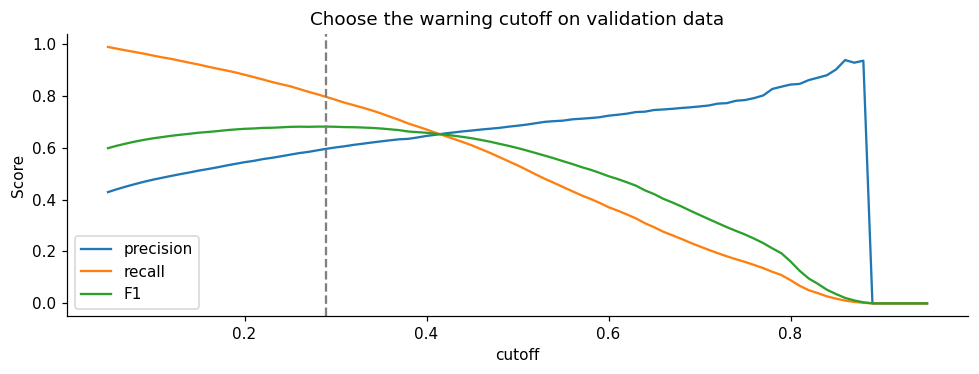

In [23]:
trade=[]
for t in threshold_grid:
    trade.append({'cutoff':t,'precision':precision_score(ydev[valid],val_p>=t,zero_division=0),
                  'recall':recall_score(ydev[valid],val_p>=t,zero_division=0),'F1':f1_score(ydev[valid],val_p>=t,zero_division=0)})
trade=pd.DataFrame(trade).set_index('cutoff');trade.plot(figsize=(9,3.5),title='Choose the warning cutoff on validation data')
plt.axvline(threshold,color='gray',ls='--');plt.ylabel('Score');plt.tight_layout();plt.show()

## 9. Refit and evaluate later years
We now refit the selected candidate on 2020–2023. We also evaluate a pre-defined core-only boosting model and a simple baseline. These show the extra value of the selected approach. We do not choose another model after reading these results.

The same claims are used for each comparison. Missing external values are handled by the training pipeline. The external measurements remain retrospective inputs.

In [24]:
selected_model=make_model(d[selected_cols],task,selected_family)
ix=fitting_ids(train,selected_family)
selected_model.fit(d.loc[ix,selected_cols],y.loc[ix])
core_model=candidate_model(d[CORE],task,'boosting').fit(d.loc[train,CORE],y[train])
predictions={}
if task=='regression':
    predictions['mean baseline']=np.full(test.sum(),y[train].mean())
    predictions['median baseline']=np.full(test.sum(),y[train].median())
    predictions['core boosting']=np.maximum(core_model.predict(d.loc[test,CORE]),0)
    predictions['selected on earlier years']=np.maximum(selected_model.predict(d.loc[test,selected_cols]),0)
    final=pd.DataFrame({k:regression_scores(y[test],p) for k,p in predictions.items()}).T
else:
    predictions['constant training share']=np.full(test.sum(),y[train].mean())
    predictions['flag every claim']=np.ones(test.sum())
    predictions['core boosting']=core_model.predict_proba(d.loc[test,CORE])[:,1]
    predictions['selected on earlier years']=selected_model.predict_proba(d.loc[test,selected_cols])[:,1]
    final=pd.DataFrame({k:classification_scores(y[test],p,threshold if k=='selected on earlier years' else .5)
                        for k,p in predictions.items()}).T
    final.loc['selected at threshold 0.50']=classification_scores(y[test],predictions['selected on earlier years'],.5)
display(final.round(3))
save_table(final,'02_later_years' if task=='regression' else '03_later_years')
p=predictions['selected on earlier years']

,precision,recall,F1,ROC-AUC,PR-AUC
constant training share,0.000,0.000,0.000,0.500,0.363
flag every claim,0.363,1.000,0.532,0.500,0.363
core boosting,0.768,0.527,0.625,0.841,0.732
selected on earlier years,0.649,0.777,0.708,0.851,0.758
selected at threshold 0.50,0.745,0.632,0.684,0.851,0.758


### 9.1 A national score can hide a regional failure
The confusion matrix counts actual mistakes. The regional table checks whether recall travels beyond the dominant state. The calibration plot compares model scores with observed shares; balanced fitting and a new event mix can make them disagree.

,claims,large-loss share,precision,recall,F1,ROC-AUC,PR-AUC
region,,,,,,,
Florida,73601,0.448,0.656,0.858,0.743,0.840,0.790
Gulf Coast,9699,0.152,0.470,0.188,0.269,0.781,0.382
Mid-Atlantic / Northeast,5444,0.087,0.425,0.356,0.387,0.823,0.371
Other states,15489,0.184,0.572,0.226,0.324,0.769,0.440


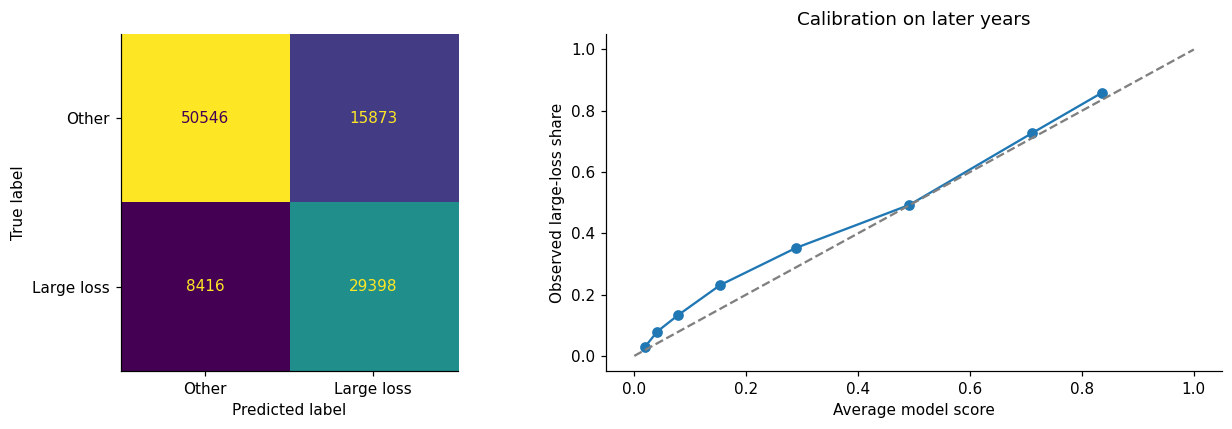

In [25]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.calibration import calibration_curve
z=d[test].copy(); z['target']=y[test];z['score']=p
regions={'Florida':['FL'],'Gulf Coast':['LA','TX','MS','AL'],
         'Mid-Atlantic / Northeast':['NJ','NY','CT','RI','MA','MD','DE','DC','NH','ME','PA']}
used=sum(regions.values(),[])
z['region']='Other states'
for label,states in regions.items(): z.loc[z.state.isin(states),'region']=label
regional=[]
for label,g in z.groupby('region'):
    regional.append({'region':label,'claims':len(g),'large-loss share':g.target.mean(),
                     **classification_scores(g.target,g.score,threshold)})
display(pd.DataFrame(regional).set_index('region').round(3))
save_table(pd.DataFrame(regional).set_index('region'),'03_regions')
fig,ax=plt.subplots(1,2,figsize=(12,4))
ConfusionMatrixDisplay.from_predictions(y[test],p>=threshold,ax=ax[0],colorbar=False,display_labels=['Other','Large loss'])
a,b=calibration_curve(y[test],p,n_bins=8,strategy='quantile')
ax[1].plot(b,a,marker='o');ax[1].plot([0,1],[0,1],'--',color='gray')
ax[1].set(xlabel='Average model score',ylabel='Observed large-loss share',title='Calibration on later years')
plt.tight_layout();plt.show()

### 9.2 Read the ROC and precision–recall curves together
ROC measures separation across both classes. Precision–recall focuses on the large-loss cases and depends on their share in the evaluation period. Curves describe the frozen model; they are not used to retune it.

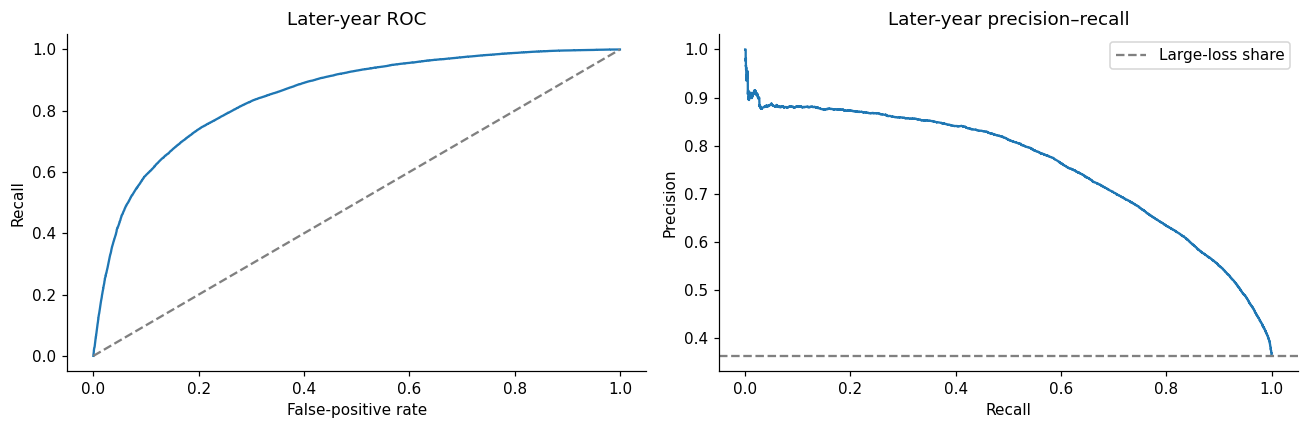

In [26]:
from sklearn.metrics import roc_curve,precision_recall_curve
fig,ax=plt.subplots(1,2,figsize=(12,4))
fpr,tpr,_=roc_curve(y[test],p);precision,recall,_=precision_recall_curve(y[test],p)
ax[0].plot(fpr,tpr);ax[0].plot([0,1],[0,1],'--',color='gray');ax[0].set(xlabel='False-positive rate',ylabel='Recall',title='Later-year ROC')
ax[1].plot(recall,precision);ax[1].axhline(y[test].mean(),ls='--',color='gray',label='Large-loss share')
ax[1].set(xlabel='Recall',ylabel='Precision',title='Later-year precision–recall');ax[1].legend()
plt.tight_layout();plt.show()

## 10. Check excluded storms
We refit the frozen model while leaving out each of the six largest named events. This checks sensitivity to event identity. It is **not** a historical forecast: training can include storms that occurred after the excluded storm. The feature choice was already informed by some development storms, so this is a sensitivity check rather than an independent model-selection test.

For every excluded event we calculate the dollar cutoff from the remaining fitting claims. We keep the previously selected warning threshold. A large change in precision or recall means the warning policy may not travel well between storms.

In [27]:
storm_rows=[]
for event in d.floodEvent.value_counts().head(6).index:
    held=d.floodEvent.eq(event); other=~held
    yy=y.copy() if task=='regression' else (d.buildingDamageAmount>=d.loc[other,'buildingDamageAmount'].quantile(.8)).astype(int)
    ix=fitting_ids(other,selected_family)
    model=make_model(d[selected_cols],task,selected_family).fit(d.loc[ix,selected_cols],yy.loc[ix])
    pp=model.predict(d.loc[held,selected_cols]) if task=='regression' else model.predict_proba(d.loc[held,selected_cols])[:,1]
    sc=regression_scores(yy[held],np.maximum(pp,0)) if task=='regression' else classification_scores(yy[held],pp,threshold)
    storm_rows.append({'storm':event,'claims':held.sum(),**sc})
storm_table=pd.DataFrame(storm_rows).set_index('storm')
display(storm_table.round(3))
save_table(storm_table,'02_storm_sensitivity' if task=='regression' else '03_storm_sensitivity')

,claims,precision,recall,F1,ROC-AUC,PR-AUC
storm,,,,,,
Hurricane Helene,53966,0.711,0.914,0.800,0.841,0.824
Hurricane Ian,42631,0.547,0.534,0.541,0.767,0.604
Hurricane Ida,26224,0.426,0.282,0.339,0.815,0.353
Hurricane Milton,18880,0.398,0.334,0.364,0.741,0.367
Hurricane Sally,7138,0.259,0.294,0.276,0.801,0.227
Hurricane Idalia,5142,0.445,0.332,0.380,0.776,0.444


### 10.1 Where does the warning rule work, and where does it not?
A national score can hide big differences. We show how much better the rule is than the simplest plan, which is to warn about every claim, and how it behaves for different building types.

In [28]:
z2=d[test].copy();z2['target']=y[test];z2['score']=p
z2['building group']=np.where(z2.occupancy=='15','condo building',np.where(z2.occupancy=='11','single family','other buildings'))
group_rows=[]
for label,g in z2.groupby('building group'):
    group_rows.append({'building group':label,'claims':len(g),'large-loss share':g.target.mean(),
        'flag-everyone F1':f1_score(g.target,np.ones(len(g))),**classification_scores(g.target,g.score,threshold)})
group_table=pd.DataFrame(group_rows).set_index('building group')
group_table['F1 gain over flagging everyone']=group_table.F1-group_table['flag-everyone F1']
display(group_table.round(3));save_table(group_table,'03_building_groups')

,claims,large-loss share,flag-everyone F1,precision,recall,F1,ROC-AUC,PR-AUC,F1 gain over flagging everyone
building group,,,,,,,,,
condo building,8538,0.396,0.567,0.510,0.895,0.650,0.814,0.751,0.083
other buildings,16339,0.302,0.464,0.593,0.733,0.655,0.840,0.688,0.191
single family,79356,0.372,0.542,0.685,0.771,0.725,0.859,0.774,0.183


## 11. What did we learn and keep?
The tables above are the evidence for the selected model. Read the later-year score together with the storm and subgroup results. An improvement on one period can fail in another.

**Why extra features may fail:** local rain does not measure coastal water level or river overflow. Track wind is measured near the storm center, not at the house. Census values describe areas. These columns can also identify familiar storm patterns rather than measure local damage. Closely related rain columns can add little new information.

**Why we stopped here:** we tested nine feature combinations and several model families, including stronger regularization. This is a limited search, not proof that further improvement is impossible. Better local water-depth and flood-extent data, careful location matching and genuinely new storm data are more useful next steps than adding many similar columns.

A large-loss label in dollars partly reflects building size. Missing damage records are excluded, which may change the study population. Regional class shares differ, so national recall can hide weak performance outside the largest region. The model scores have not been proved to be reliable probabilities.

In [29]:
answer=final.loc['selected on earlier years']
if task=='regression':
    display(Markdown(f"**Answer to RQ1.** Using **{selected}**, later-year R² is **{answer['R2']:.3f}**, "
                     f"average absolute error is **${answer['MAE $']:,.0f}**, and median error is **${answer['median error $']:,.0f}**. "
                     "These scores describe the tested period. The event-level results show how much the answer changes between storms."))
else:
    display(Markdown(f"**Answer to RQ2.** Using **{selected}** and the validation threshold **{threshold:.2f}**, "
                     f"later-year precision is **{answer.precision:.1%}**, recall **{answer.recall:.1%}**, "
                     f"F1 **{answer.F1:.3f}**, and ROC-AUC **{answer['ROC-AUC']:.3f}**. "
                     "Use the regional table to judge where this warning rule is useful."))
if task=='regression':
    delta=answer['R2']-final.loc['core boosting','R2']
    display(Markdown(f"**Added value on later years:** R² changes by **{delta:+.3f}** from the core boosting model. "
                     "A small or negative change means the development winner did not provide a clear improvement in this period. "
                     "The development period includes different storms and fewer examples of very large buildings."))
else:
    fixed=final.loc['selected at threshold 0.50','F1']
    display(Markdown(f"**Effect of the warning threshold:** F1 is **{fixed:.3f}** at 0.50 and **{answer.F1:.3f}** at the threshold chosen on earlier years. "
                     "This is a change in how many claims are flagged. It does not improve the underlying ranking or prove that model scores are calibrated probabilities."))

**Answer to RQ2.** Using **core + claim counts | boosting** and the validation threshold **0.29**, later-year precision is **64.9%**, recall **77.7%**, F1 **0.708**, and ROC-AUC **0.851**. Use the regional table to judge where this warning rule is useful.

**Effect of the warning threshold:** F1 is **0.684** at 0.50 and **0.708** at the threshold chosen on earlier years. This is a change in how many claims are flagged. It does not improve the underlying ranking or prove that model scores are calibrated probabilities.

### 11.1 Decision ledger and the next question

| Experiment | What we learned to check |
|---|---|
| Flag none or all | Accuracy, recall and warning cost are different |
| Shallow then deeper tree | Depth needs fitting-period validation |
| Naive Bayes | Simplicity has distribution and independence assumptions |
| Raw then scaled KNN | Distance depends on units |
| k, metric and PCA | A textbook preparation step must earn its place |
| Logistic and SVM | Read the score, boundary, cost and assumptions |
| Forest/boosting extensions | Complexity is justified only by measured added value |
| External sources | A larger input table can still transfer poorly |
| Warning cutoff | Ranking and the decision to flag are separate |
| Regions and excluded storms | National results may not travel |

**Bridge to notebook 04:** prediction is supervised because it uses a damage label. We next remove that label from fitting and ask whether the input features form meaningful groups on their own.

### Result in plain English

The model chosen on the earlier years finds **77.7%** of the large-loss claims in the later years. **64.9%** of its warnings are correct (F1 **0.708**, ROC-AUC **0.851**). Warning about every claim gives F1 **0.532**, so the model adds **+0.175**. Recall is **85.8%** in Florida and **18.8%** on the Gulf Coast.

The national result hides a regional gap. Florida has many large losses, so a warning there is easy to get right. Other regions have fewer large losses and the rule works less well. Changing the cutoff moves the balance between missed losses and false alarms; it does not add new information. The comparison bands do not allow for choosing the winner from many models, so a higher validation score is a hint, not proof.